# 02 - Backtest results and final forecast

Reads the outputs of `scripts/run_backtest.py` (expanding-window rolling origin, 35 quarterly cutoffs from 2017-01 to
2025-07, horizons 1-12) and `scripts/forecast.py`. Nothing here is re-tuned: this notebook only reports.

**Models**

| Model | Type | Uses macro drivers? |
|---|---|---|
| Naive | baseline: last observed value | no |
| SeasonalNaive | baseline: value 12 months earlier | no |
| AutoETS | exponential smoothing, automatic selection (statsforecast) | no |
| AutoARIMA | seasonal ARIMA, automatic selection (statsforecast) | no |
| LightGBM | direct multi-horizon gradient boosting on target lags, label = change vs. origin | no |
| LightGBM+exog | as above + lagged Selic, IPCA 12m, lending rate, unemployment, IBC-Br, debt-to-income, concessions | yes (only values published at forecast time) |
| Ensemble | equal-weight mean of AutoETS and LightGBM+exog | via LightGBM+exog |

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from bcb_forecast import plots
from bcb_forecast.backtest import summarize, skill_vs
from bcb_forecast.data import PROJECT_ROOT, TARGET
from bcb_forecast.features import DEFAULT_EXOG, make_supervised
from bcb_forecast.models import LGBM_PARAMS

warnings.filterwarnings("ignore")
plots.style()
ART, FIG = PROJECT_ROOT / "artifacts", PROJECT_ROOT / "reports" / "figures"
panel = pd.read_csv(PROJECT_ROOT / "data" / "panel.csv", index_col=0, parse_dates=True).asfreq("MS")
bt = pd.read_csv(ART / "backtest_conformal.csv", parse_dates=["ds", "cutoff"])
bt_native = pd.read_csv(ART / "backtest.csv", parse_dates=["ds", "cutoff"])
print(bt["cutoff"].nunique(), "cutoffs:", bt["cutoff"].min().date(), "->", bt["cutoff"].max().date())

35 cutoffs: 2017-01-01 -> 2025-07-01


## 1. Point accuracy

MAE/RMSE in percentage points of the default rate. MASE scales each error by the in-sample MAE of a one-step naive
forecast, so values > 1 are expected when pooling horizons up to 12 months; what matters is the comparison between
models. `MAE_skill_vs_naive` = 1 - MAE / MAE(Naive).

In [2]:
overall = summarize(bt)[["MAE", "RMSE", "MAPE", "MASE", "bias", "n"]]
overall["MAE_skill_vs_naive"] = skill_vs(overall, "Naive")
overall.sort_values("MAE").round(3)

,MAE,RMSE,MAPE,MASE,bias,n,MAE_skill_vs_naive
model,,,,,,,
Ensemble,0.278,0.401,7.272,3.535,0.106,420,0.136
AutoETS,0.290,0.431,7.738,3.692,0.050,420,0.098
LightGBM+exog,0.295,0.408,7.620,3.734,0.163,420,0.085
Naive,0.322,0.437,8.391,4.082,0.059,420,0.000
AutoARIMA,0.355,0.498,9.621,4.502,0.037,420,-0.101
LightGBM,0.363,0.508,9.396,4.593,0.123,420,-0.127
SeasonalNaive,0.496,0.599,13.013,6.259,0.082,420,-0.542


In [3]:
per_h = summarize(bt, ["model", "horizon"])
mae_h = per_h["MAE"].unstack("horizon")
(1 - mae_h / mae_h.loc["Naive"]).loc[overall.sort_values("MAE").index].round(2).iloc[:, [0, 2, 5, 8, 11]]

horizon,1,3,6,9,12
model,,,,,
Ensemble,0.31,0.23,0.12,0.11,0.08
AutoETS,0.13,0.19,0.12,0.09,0.05
LightGBM+exog,0.28,0.19,0.07,0.03,0.01
Naive,0.00,0.00,0.00,0.00,0.00
AutoARIMA,0.19,0.01,-0.09,-0.15,-0.18
LightGBM,0.23,-0.03,-0.11,-0.19,-0.18
SeasonalNaive,-5.57,-1.79,-0.64,-0.22,0.00


Skill vs. Naive by horizon (positive = better than "no change"), at h = 1, 3, 6, 9, 12.

## 2. Are the uncertainty bands trustworthy?

Native intervals come from the models themselves (statsforecast analytic intervals; LightGBM quantile regression).
Online conformal intervals are `forecast ± q`, where `q` is the empirical quantile of the same model's past absolute
errors at the same horizon, using **only errors already observable at the forecast date** (first 8 per horizon are
warm-up). Both are scored on the same 306 forecasts per model.

In [4]:
keys = ["model", "cutoff", "horizon"]
same_rows = bt_native.merge(bt.loc[bt["lo_80"].notna(), keys], on=keys)  # identical forecasts
nat = summarize(same_rows)
conf = summarize(bt)
pre = summarize(bt[bt["ds"] < "2025-01-01"])
cmp = pd.DataFrame({
    "native 80%": nat["coverage_80"], "native 95%": nat["coverage_95"],
    "conformal 80%": conf["coverage_80"], "conformal 95%": conf["coverage_95"],
    "conformal width 80% (p.p.)": conf["width_80"], "n": conf["n_intervals"],
    "conformal 80%, targets < 2025": pre["coverage_80"],
}).reindex(overall.sort_values("MAE").index)
cmp.round(2)

,native 80%,native 95%,conformal 80%,conformal 95%,conformal width 80% (p.p.),n,"conformal 80%, targets < 2025"
model,,,,,,,
Ensemble,NaN,NaN,0.68,0.90,0.70,306,0.78
AutoETS,0.65,0.88,0.68,0.89,0.75,306,0.74
LightGBM+exog,0.38,0.60,0.68,0.87,0.76,306,0.78
Naive,0.53,0.74,0.65,0.89,0.83,306,0.74
AutoARIMA,0.62,0.91,0.68,0.90,0.95,306,0.69
LightGBM,0.42,0.57,0.67,0.85,0.96,306,0.73
SeasonalNaive,0.62,0.87,0.57,0.81,1.24,306,0.62


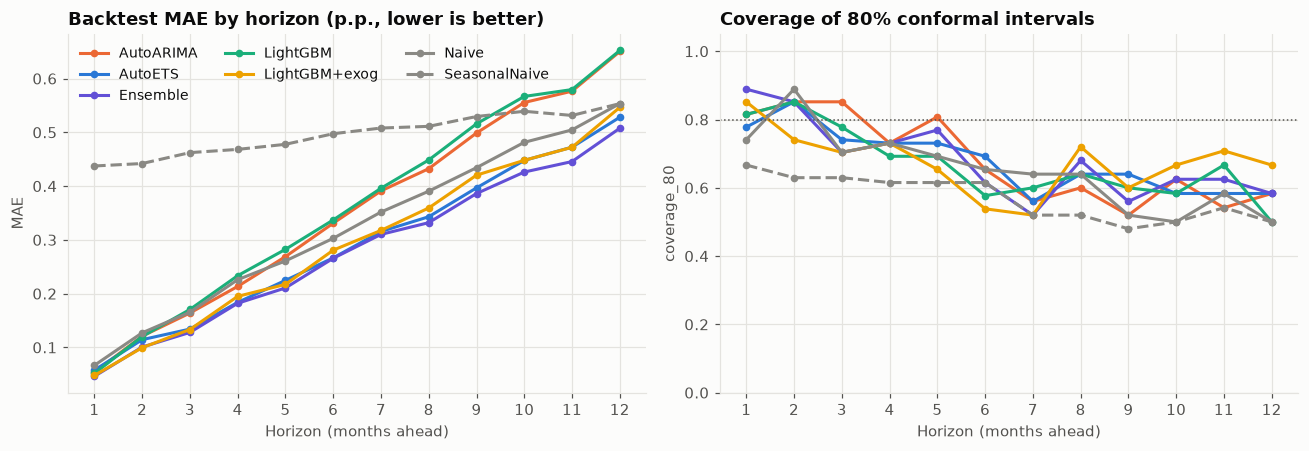

In [5]:
fig = plt.figure(figsize=(12, 4.2))
ax1, ax2 = fig.subplots(1, 2)
plots.metric_by_horizon(per_h, "MAE", "Backtest MAE by horizon (p.p., lower is better)", ax1)
plots.metric_by_horizon(per_h, "coverage_80", "Coverage of 80% conformal intervals", ax2)
ax2.axhline(0.8, color=plots.INK_2, lw=1, ls=":"); ax2.set_ylim(0, 1.05); ax2.get_legend().remove()
fig.tight_layout()

## 3. What the backtest forecasts looked like

Ensemble forecasts with 80% conformal bands from a few origins (bands appear once enough past errors exist).

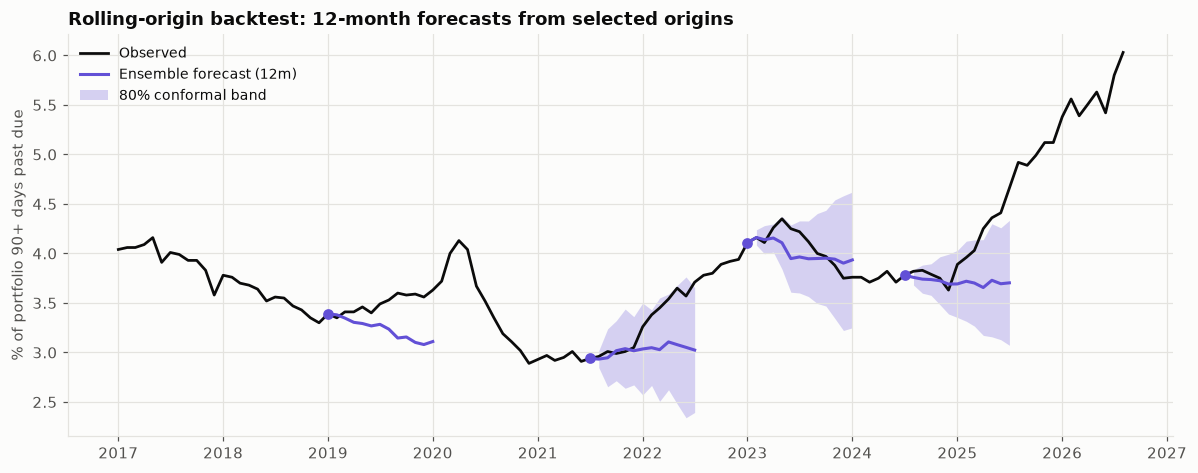

In [6]:
ens = bt[bt["model"] == "Ensemble"]
show = [pd.Timestamp(c) for c in ["2019-01-01", "2021-07-01", "2023-01-01", "2024-07-01"]]
fig, ax = plt.subplots(figsize=(11, 4.4))
y = panel[TARGET]
ax.plot(y.loc["2017":].index, y.loc["2017":], color=plots.INK, lw=1.8, label="Observed")
for i, c in enumerate(show):
    g = ens[ens["cutoff"] == c]
    ax.plot([c, *g["ds"]], [y[c], *g["mean"]], color=plots.MODEL_COLORS["Ensemble"], lw=2,
            label="Ensemble forecast (12m)" if i == 0 else None)
    if g["lo_80"].notna().all():
        ax.fill_between(g["ds"], g["lo_80"], g["hi_80"], color=plots.MODEL_COLORS["Ensemble"], alpha=0.25,
                        lw=0, label="80% conformal band" if i == 1 else None)
    ax.plot(c, y[c], "o", color=plots.MODEL_COLORS["Ensemble"], ms=6)
ax.set_title("Rolling-origin backtest: 12-month forecasts from selected origins")
ax.set_ylabel("% of portfolio 90+ days past due")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "backtest_paths.png", dpi=110)

## 4. Which drivers does the ML model use?

Gain importance of the LightGBM+exog model for a 6-month horizon, trained on all data (descriptive only:
importance is not causality, and correlated drivers share credit).

In [7]:
X, label = make_supervised(panel, 6, exog=DEFAULT_EXOG)
mask = label.notna()
m = lgb.LGBMRegressor(**{**LGBM_PARAMS, "importance_type": "gain"}).fit(X[mask], label[mask])
imp = pd.Series(m.feature_importances_, index=X.columns).sort_values(ascending=False)
(imp / imp.sum()).head(12).round(3).to_frame("share of gain")

,share of gain
concessions_hh_diff_12,0.182
lending_rate_hh_diff_12,0.152
debt_to_income_hh_diff_12,0.109
ibc_br_sa,0.106
selic_target_diff_12,0.062
y,0.047
selic_target_diff_3,0.043
lending_rate_hh_diff_3,0.041
lending_rate_hh,0.041
debt_to_income_hh_diff_3,0.027


## 5. Final forecast (origin = last published month)

In [8]:
fc = pd.read_csv(ART / "final_forecast.csv", parse_dates=["ds"])
fc.assign(month=fc["ds"].dt.strftime("%Y-%m")).set_index("month")[
    ["mean", "lo_80", "hi_80", "lo_95", "hi_95", "AutoETS", "LightGBM+exog"]].round(2)

,mean,lo_80,hi_80,lo_95,hi_95,AutoETS,LightGBM+exog
month,,,,,,,
2026-09,6.01,5.93,6.09,5.82,6.20,5.93,6.08
2026-10,6.01,5.88,6.14,5.45,6.57,5.95,6.07
2026-11,6.03,5.83,6.22,5.31,6.75,5.95,6.11
2026-12,6.04,5.75,6.34,5.15,6.93,5.88,6.21
2027-01,6.17,5.83,6.51,5.14,7.21,6.05,6.30
2027-02,6.23,5.78,6.68,5.04,7.41,6.07,6.38
2027-03,6.22,5.75,6.70,5.01,7.44,6.00,6.44
2027-04,6.26,5.74,6.78,4.95,7.57,6.12,6.40
2027-05,6.36,5.77,6.96,5.04,7.68,6.14,6.58


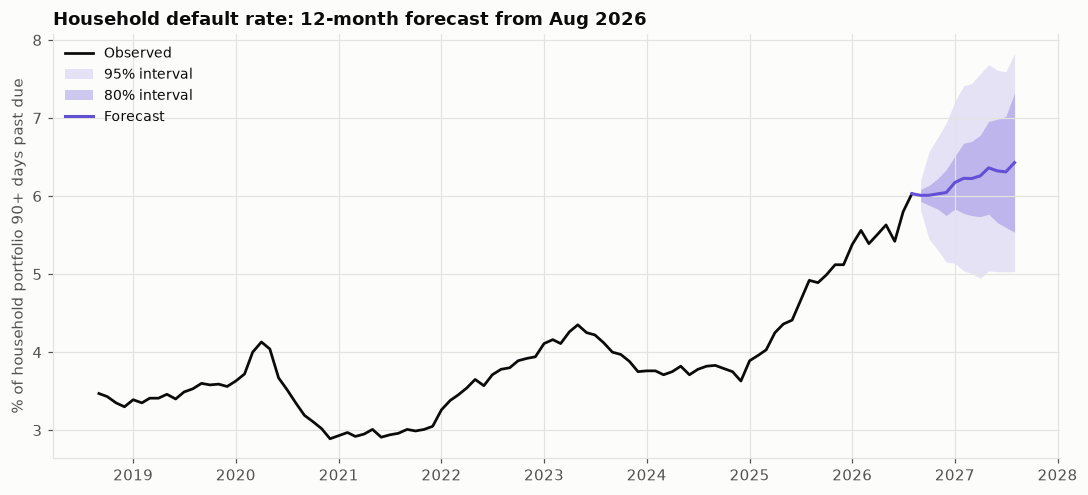

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.6))
plots.fan_chart(y, fc, f"Household default rate: 12-month forecast from {y.index[-1]:%b %Y}", ax=ax,
                color=plots.MODEL_COLORS["Ensemble"], history_months=96)
fig.tight_layout()

## Takeaways for the credit / treasury team

1. **"No change" is a strong benchmark, and only some models beat it.** Over 420 backtest forecasts per model, the
   Ensemble (AutoETS + LightGBM with macro drivers) has MAE 0.278 p.p. vs. 0.322 for Naive (**-14%**). AutoETS alone
   (-10%) and LightGBM+exog (-9%) also beat it; AutoARIMA, LightGBM without drivers and Seasonal-naive do not.
2. **Macro drivers carry real signal.** Adding lagged, publication-aware drivers cuts LightGBM's MAE from 0.363 to
   0.295 p.p. (-19%). The model leans on 12-month changes in credit concessions, household lending rates and
   debt-to-income, consistent with the lead-lag analysis in notebook 01.
3. **Gains shrink with horizon.** The Ensemble is 31% better than Naive at 1 month but only ~8% at 12 months.
   12-month-ahead errors average ~0.5 p.p., so long-range numbers should feed scenario ranges, not single points.
4. **Model-implied intervals are too narrow; calibrated ones are better but still optimistic.** On the same
   forecasts, LightGBM+exog's quantile bands covered only 38% of outcomes vs. a nominal 80% (Naive 53%, AutoETS 65%).
   Online conformal bands lift this to 65-68% for all but Seasonal-naive, and to 69-78% for target months before
   2025. The shortfall comes from the 2025-26 surge: errors are not stable over time, and the models did not
   anticipate that turning point (see the 2024-07 origin above). **Treat the 80% band as closer to a 2-in-3 band
   during regime changes.**
5. **Current outlook (origin Aug 2026, 6.03%).** Central path: roughly flat at ~6.0% through Dec 2026, drifting up to
   ~6.4% by Aug 2027. The 80% band for Aug 2027 is 5.5%-7.3%. The two members disagree on direction (AutoETS flat at
   ~6.1%, LightGBM+exog rising to ~6.8% because rates and indebtedness are still elevated), which is itself
   useful information: **plan provisions on the central path, and stress-test pricing and capital at least at the
   upper 80% bound (~7.3%), with the 95% bound (~7.8%) as a severe scenario**.

Caveat: the Ensemble members were chosen after seeing the individual backtest results (mild selection bias); its edge
over AutoETS alone is small (0.278 vs. 0.290 p.p.).